# Lab 04 - Constraint Satisfaction Problem: Graph Coloring

## Bài 1 - Biểu diễn CSP và sinh đồ thị cần tô màu

### 1. Sinh dữ liệu đồ thị phẳng

Ta sinh `n = 10` điểm nguyên ngẫu nhiên trong mặt phẳng, sắp xếp theo hoành độ rồi dùng phép tam giác hóa [Delaunay](https://en.wikipedia.org/wiki/Delaunay_triangulation) để tạo đồ thị phẳng. Seed được cố định để hình học, tập cạnh và các kết quả so sánh thuật toán có thể tái lập.

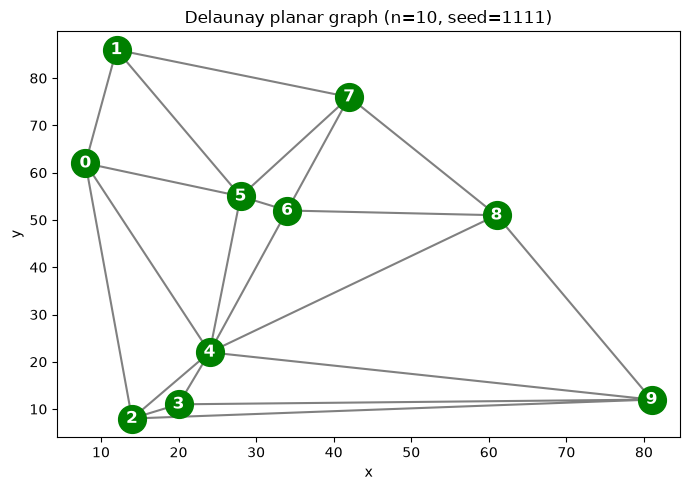

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay

SEED = 1111
np.random.seed(SEED)

# Create points and sort them by x-coordinate.
n = 10
points = np.random.randint(100, size=(n, 2))
o = np.argsort(points[:,0])
points = points[o,:]


# Build the planar graph by Delaunay triangulation.
tri = Delaunay(points)


# Plot the generated graph.
plt.figure(figsize=(7, 5))
plt.triplot(points[:,0], points[:,1], tri.simplices, color="gray")
plt.plot(points[:,0], points[:,1], 'o', color="green", markersize=20)

for i in range(len(points)):
    plt.annotate(
        i, points[i, :], color='white', fontsize='large', weight='bold',
        horizontalalignment='center', verticalalignment='center'
    )

plt.title(f'Delaunay planar graph (n={n}, seed={SEED})')
plt.xlabel('x')
plt.ylabel('y')
plt.tight_layout()
plt.show()

Từ kết quả Delaunay, `vertex_neighbor_vertices` cho biết các đỉnh kề với từng đỉnh. Danh sách `neighbors[i]` chứa toàn bộ đỉnh nối trực tiếp với đỉnh `i`. Vì đây là đồ thị vô hướng, quan hệ láng giềng phải đối xứng. Tập cạnh chuẩn hóa chỉ giữ cặp `(i, j)` khi `i < j`, nhờ đó mỗi cạnh và mỗi ràng buộc khác màu chỉ xuất hiện đúng một lần.

In [2]:
(indptr, indices) = tri.vertex_neighbor_vertices

neighbors = []

for k in range(len(indptr)-1):
    neighbors.append(np.sort(indices[indptr[k]:indptr[k+1]]))

edges = sorted(
    (i, int(j))
    for i, adjacent_vertices in enumerate(neighbors)
    for j in adjacent_vertices
    if i < int(j)
)
num_edges = len(edges)
average_degree = sum(len(adjacent_vertices) for adjacent_vertices in neighbors) / n

# Sanity checks for an undirected graph and the i < j edge convention.
assert all(i in neighbors[j] for i, j in edges)
assert sum(len(adjacent_vertices) for adjacent_vertices in neighbors) == 2 * num_edges

print(f'n = {n}, seed = {SEED}')
print(f'Number of undirected edges = {num_edges}')
print(f'Average degree = {average_degree:.2f}')
print('Neighbor list:')
for vertex, adjacent_vertices in enumerate(neighbors):
    print(f'  {vertex}: {adjacent_vertices.tolist()}')
print('Edges (stored once with i < j):')
print(edges)

n = 10, seed = 1111
Number of undirected edges = 21
Average degree = 4.20
Neighbor list:
  0: [1, 2, 4, 5]
  1: [0, 5, 7]
  2: [0, 3, 4, 9]
  3: [2, 4, 9]
  4: [0, 2, 3, 5, 6, 8, 9]
  5: [0, 1, 4, 6, 7]
  6: [4, 5, 7, 8]
  7: [1, 5, 6, 8]
  8: [4, 6, 7, 9]
  9: [2, 3, 4, 8]
Edges (stored once with i < j):
[(0, 1), (0, 2), (0, 4), (0, 5), (1, 5), (1, 7), (2, 3), (2, 4), (2, 9), (3, 4), (3, 9), (4, 5), (4, 6), (4, 8), (4, 9), (5, 6), (5, 7), (6, 7), (6, 8), (7, 8), (8, 9)]


Kết quả trên mô tả đầy đủ đồ thị đầu vào: dòng mang nhãn `0` là các láng giềng của đỉnh 0. Tổng bậc phải bằng hai lần số cạnh; hai lệnh `assert` kiểm tra tính đối xứng và bất biến này trước khi tạo CSP.

### 2. Mô hình hóa bài toán dưới dạng CSP

Bài toán tô màu đồ thị được biểu diễn bởi bộ ba $(X, D, C)$:

- **Tập biến $X$:** $X = \{0, 1, \ldots, n-1\}$; mỗi biến ứng với một đỉnh của đồ thị. Trong mã, tên biến được lưu dưới dạng chuỗi để tương thích với các hàm tìm kiếm phía sau.
- **Miền giá trị $D$:** với mỗi đỉnh $i$, $D_i$ là tập màu có thể gán. Ta khảo sát hai cấu hình gồm 4 màu (`red`, `blue`, `green`, `orange`) và 3 màu (`red`, `blue`, `green`).
- **Tập ràng buộc $C$:** với mỗi cạnh vô hướng $(i, j)$, $C_{ij}: color(i) \ne color(j)$. Chỉ lưu cạnh có `i < j` để không kiểm tra trùng một ràng buộc ở cả hai chiều.

Một **phép gán đầy đủ** chỉ yêu cầu mọi biến đều có giá trị. Một **phép gán hợp lệ** còn phải thỏa tất cả ràng buộc. Vì vậy, phép gán đầy đủ chưa chắc là nghiệm CSP; nghiệm phải đồng thời đầy đủ và nhất quán.

In [3]:
COLORS_4 = ('red', 'blue', 'green', 'orange')
COLORS_3 = ('red', 'blue', 'green')

def build_graph_coloring_csp(neighbors, colors):
    """Create the X, D, C representation for an undirected graph."""
    variables = [str(vertex) for vertex in range(len(neighbors))]
    # Give every variable its own list so later domain pruning is safe.
    domains = {variable: list(colors) for variable in variables}
    constraints = tuple(
        (str(i), str(int(j)))
        for i, adjacent_vertices in enumerate(neighbors)
        for j in adjacent_vertices
        if i < int(j)
    )
    return {
        'variables': variables,
        'domains': domains,
        'constraints': constraints,
    }

csp_4_colors = build_graph_coloring_csp(neighbors, COLORS_4)
csp_3_colors = build_graph_coloring_csp(neighbors, COLORS_3)

# Keep the four-color model as the default for the existing search cells below.
csp = csp_4_colors
variables = csp['variables']
domains = csp['domains']
constraints = csp['constraints']
domain = list(COLORS_4)

assert len(constraints) == num_edges
assert all(int(i) < int(j) for i, j in constraints)

for label, model in [('4 colors', csp_4_colors), ('3 colors', csp_3_colors)]:
    print(
        f'{label}: |X|={len(model["variables"])}, '
        f'|D_i|={len(model["domains"]["0"])}, '
        f'|C|={len(model["constraints"])}'
    )
    print(f'  D_0 = {model["domains"]["0"]}')

print('Sample constraints:', constraints[:10])

4 colors: |X|=10, |D_i|=4, |C|=21
  D_0 = ['red', 'blue', 'green', 'orange']
3 colors: |X|=10, |D_i|=3, |C|=21
  D_0 = ['red', 'blue', 'green']
Sample constraints: (('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5'), ('1', '7'), ('2', '3'), ('2', '4'), ('2', '9'), ('3', '4'))


## Bài 2 - Kiểm tra tính đầy đủ và nhất quán

Một phép gán được lưu bằng `dict`, trong đó khóa là tên biến và giá trị là màu được gán. Ví dụ `{}` là phép gán rỗng.

- `complete(assignment, csp)` chỉ trả về `True` khi tập khóa của phép gán đúng bằng tập biến $X$. Hàm này không kiểm tra các ràng buộc.
- `consistent(assignment, csp)` trả về `True` khi mọi giá trị đã gán đều thuộc miền tương ứng và không có cạnh nào nối hai đỉnh cùng màu. Hàm áp dụng được cho cả phép gán từng phần.
- `is_solution(assignment, csp)` chỉ trả về `True` khi phép gán đồng thời đầy đủ và nhất quán. Vì vậy, một phép gán đầy đủ chưa chắc là nghiệm CSP.

In [4]:
def complete(assignment, csp):
    """Return True only when every CSP variable is assigned exactly once."""
    return set(assignment) == set(csp['variables'])

In [5]:
def consistent(assignment, csp):
    """Check domain membership and all constraints whose endpoints are assigned."""
    for variable, value in assignment.items():
        if variable not in csp['domains'] or value not in csp['domains'][variable]:
            return False

    for first, second in csp['constraints']:
        if first in assignment and second in assignment:
            if assignment[first] == assignment[second]:
                return False

    return True

def is_solution(assignment, csp):
    """A CSP solution must be both complete and consistent."""
    return complete(assignment, csp) and consistent(assignment, csp)

all_red_assignment = {variable: 'red' for variable in csp['variables']}
known_valid_solution = {
    '0': 'red', '1': 'blue', '2': 'blue', '3': 'red', '4': 'green',
    '5': 'orange', '6': 'red', '7': 'green', '8': 'blue', '9': 'orange',
}

test_cases = [
    {
        'name': 'Empty assignment',
        'assignment': {},
        'expected': (False, True, False),
    },
    {
        'name': 'Consistent partial assignment',
        'assignment': {'0': 'red', '1': 'blue'},
        'expected': (False, True, False),
    },
    {
        'name': 'Adjacent vertices share a color',
        'assignment': {'0': 'red', '1': 'red'},
        'expected': (False, False, False),
    },
    {
        'name': 'Assigned value is outside the domain',
        'assignment': {'0': 'purple'},
        'expected': (False, False, False),
    },
    {
        'name': 'Complete but conflicting assignment',
        'assignment': all_red_assignment,
        'expected': (True, False, False),
    },
    {
        'name': 'Complete and valid solution',
        'assignment': known_valid_solution,
        'expected': (True, True, True),
    },
]

print(f'{"Test case":38} | Expected (C, K, S) | Actual (C, K, S) | Result')
print('-' * 91)
for case in test_cases:
    assignment = case['assignment']
    actual = (
        complete(assignment, csp),
        consistent(assignment, csp),
        is_solution(assignment, csp),
    )
    result = 'PASS' if actual == case['expected'] else 'FAIL'
    print(f'{case["name"]:38} | {str(case["expected"]):18} | {str(actual):16} | {result}')
    assert actual == case['expected'], case['name']

print('\nC = complete, K = consistent, S = is_solution')
print(f'Passed {len(test_cases)}/{len(test_cases)} test cases.')

Test case                              | Expected (C, K, S) | Actual (C, K, S) | Result
-------------------------------------------------------------------------------------------
Empty assignment                       | (False, True, False) | (False, True, False) | PASS
Consistent partial assignment          | (False, True, False) | (False, True, False) | PASS
Adjacent vertices share a color        | (False, False, False) | (False, False, False) | PASS
Assigned value is outside the domain   | (False, False, False) | (False, False, False) | PASS
Complete but conflicting assignment    | (True, False, False) | (True, False, False) | PASS
Complete and valid solution            | (True, True, True) | (True, True, True) | PASS

C = complete, K = consistent, S = is_solution
Passed 6/6 test cases.


## Bài 3 - Backtracking Search, MRV và LCV

Ba cấu hình được so sánh trên đúng cùng đồ thị, thứ tự màu và seed:

1. **Backtracking:** chọn biến chưa gán đầu tiên và duyệt màu theo thứ tự miền.
2. **Backtracking + MRV:** chọn biến có ít giá trị còn hợp lệ nhất; nếu hòa, giữ thứ tự biến ban đầu.
3. **Backtracking + MRV + LCV:** sau khi chọn biến bằng MRV, thử trước màu loại ít lựa chọn hợp lệ nhất khỏi các láng giềng chưa gán.

Trong phần này, `COUNT` được định nghĩa là **số lần thử một cặp biến-giá trị**. `nodes` là số trạng thái/phép gán từng phần được mở rộng, bao gồm nút gốc và nút nghiệm.

In [6]:
def build_constraint_neighbors(csp):
    """Build an adjacency map from the binary not-equal constraints."""
    neighbor_map = {variable: set() for variable in csp['variables']}
    for first, second in csp['constraints']:
        neighbor_map[first].add(second)
        neighbor_map[second].add(first)
    return neighbor_map

def legal_values(variable, assignment, csp, neighbor_map=None):
    """Return domain values that do not conflict with assigned neighbors."""
    if neighbor_map is None:
        neighbor_map = build_constraint_neighbors(csp)
    used_by_neighbors = {
        assignment[neighbor]
        for neighbor in neighbor_map[variable]
        if neighbor in assignment
    }
    return [
        value for value in csp['domains'][variable]
        if value not in used_by_neighbors
    ]

def select_unassigned_var(assignment, csp, strategy='first', neighbor_map=None):
    """Select the next variable using the baseline or MRV strategy."""
    unassigned = [
        variable for variable in csp['variables']
        if variable not in assignment
    ]
    if not unassigned:
        return None
    if strategy == 'first':
        return unassigned[0]
    if strategy == 'mrv':
        if neighbor_map is None:
            neighbor_map = build_constraint_neighbors(csp)
        variable_position = {
            variable: index for index, variable in enumerate(csp['variables'])
        }
        return min(
            unassigned,
            key=lambda variable: (
                len(legal_values(variable, assignment, csp, neighbor_map)),
                variable_position[variable],
            ),
        )
    raise ValueError(f'Unknown variable strategy: {strategy}')

def order_domain_values(variable, assignment, csp, strategy='domain', neighbor_map=None):
    """Order a variable's values by domain order or the LCV heuristic."""
    values = list(csp['domains'][variable])
    if strategy == 'domain':
        return values
    if strategy != 'lcv':
        raise ValueError(f'Unknown value strategy: {strategy}')
    if neighbor_map is None:
        neighbor_map = build_constraint_neighbors(csp)

    def eliminated_neighbor_values(value):
        trial_assignment = dict(assignment)
        trial_assignment[variable] = value
        # An immediately inconsistent value must be considered last.
        if not consistent(trial_assignment, csp):
            return float('inf')
        eliminated = 0
        for neighbor in neighbor_map[variable]:
            if neighbor in assignment:
                continue
            before = legal_values(neighbor, assignment, csp, neighbor_map)
            after = legal_values(neighbor, trial_assignment, csp, neighbor_map)
            eliminated += len(before) - len(after)
        return eliminated

    # Python's sort is stable, so domain order resolves equal LCV scores.
    return sorted(values, key=eliminated_neighbor_values)

sample_assignment = {'0': 'red', '1': 'blue'}
sample_neighbors = build_constraint_neighbors(csp)
print('Sample partial assignment:', sample_assignment)
print('  first variable =', select_unassigned_var(sample_assignment, csp, 'first', sample_neighbors))
print('  MRV variable   =', select_unassigned_var(sample_assignment, csp, 'mrv', sample_neighbors))

Sample partial assignment: {'0': 'red', '1': 'blue'}
  first variable = 2
  MRV variable   = 5


In [7]:
from time import perf_counter

COUNT = 0

def backtrack_search(csp, variable_strategy='first', value_strategy='domain', verbose=False):
    """Solve a finite graph-coloring CSP and return the solution with metrics."""
    global COUNT
    neighbor_map = build_constraint_neighbors(csp)
    stats = {'count': 0, 'nodes': 0}

    def backtrack(assignment):
        stats['nodes'] += 1
        if complete(assignment, csp):
            return dict(assignment) if consistent(assignment, csp) else None

        variable = select_unassigned_var(
            assignment, csp, variable_strategy, neighbor_map
        )
        values = order_domain_values(
            variable, assignment, csp, value_strategy, neighbor_map
        )

        for value in values:
            stats['count'] += 1
            assignment[variable] = value
            if verbose:
                print(f'Try #{stats["count"]}: {assignment}')
            if consistent(assignment, csp):
                result = backtrack(assignment)
                if result is not None:
                    return result
            del assignment[variable]

        return None

    labels = {
        ('first', 'domain'): 'Backtracking',
        ('mrv', 'domain'): 'Backtracking + MRV',
        ('mrv', 'lcv'): 'Backtracking + MRV + LCV',
    }
    start = perf_counter()
    solution = backtrack({})
    runtime_s = perf_counter() - start
    COUNT = stats['count']

    success = solution is not None and is_solution(solution, csp)
    return {
        'algorithm': labels.get(
            (variable_strategy, value_strategy),
            f'Backtracking ({variable_strategy}, {value_strategy})',
        ),
        'problem': 'graph_coloring',
        'n': len(csp['variables']),
        'num_colors': len(csp['domains'][csp['variables'][0]]),
        'success': success,
        'runtime_s': runtime_s,
        'count': stats['count'],
        'nodes': stats['nodes'],
        'assignment': solution,
    }

### So sánh trên cùng đồ thị

Mỗi cấu hình dưới đây nhận đúng cùng tập đỉnh, cạnh, thứ tự màu và seed. Cả miền 4 màu và 3 màu được chạy để quan sát tác động của miền hẹp hơn. Thời gian rất nhỏ với `n = 10`, vì vậy `COUNT` và `nodes` là chỉ số ổn định hơn cho so sánh này.

In [8]:
search_configurations = [
    ('first', 'domain'),
    ('mrv', 'domain'),
    ('mrv', 'lcv'),
]
color_models = [
    ('4 colors', csp_4_colors),
    ('3 colors', csp_3_colors),
]

backtracking_results = []
for color_label, model in color_models:
    for variable_strategy, value_strategy in search_configurations:
        result = backtrack_search(model, variable_strategy, value_strategy)
        result['color_model'] = color_label
        if result['success']:
            assert is_solution(result['assignment'], model)
        else:
            assert result['assignment'] is None
        backtracking_results.append(result)

print(
    f'{"Color model":11} | {"Algorithm":27} | Success | '
    f'{"COUNT":7} | {"Nodes":7} | {"Time (ms)":10}'
)
print('-' * 88)
for result in backtracking_results:
    print(
        f'{result["color_model"]:11} | {result["algorithm"]:27} | '
        f'{str(result["success"]):7} | {result["count"]:7d} | '
        f'{result["nodes"]:7d} | {result["runtime_s"] * 1000:10.3f}'
    )

selected_result = next(
    result for result in backtracking_results
    if result['color_model'] == '4 colors'
    and result['algorithm'] == 'Backtracking + MRV + LCV'
)
res = selected_result['assignment']

print('\nSelected solution validation:')
print('  complete   =', complete(res, csp_4_colors))
print('  consistent =', consistent(res, csp_4_colors))
print('  solution   =', is_solution(res, csp_4_colors))

Color model | Algorithm                   | Success | COUNT   | Nodes   | Time (ms) 


----------------------------------------------------------------------------------------
4 colors    | Backtracking                | True    |      23 |      11 |      0.411
4 colors    | Backtracking + MRV          | True    |      24 |      11 |      0.561
4 colors    | Backtracking + MRV + LCV    | True    |      10 |      11 |      1.631
3 colors    | Backtracking                | False   |     210 |      70 |      1.991
3 colors    | Backtracking + MRV          | False   |     102 |      34 |      1.654
3 colors    | Backtracking + MRV + LCV    | False   |     102 |      34 |      2.896

Selected solution validation:
  complete   = True
  consistent = True
  solution   = True


### Nhận xét kết quả và trực quan hóa nghiệm

- Với miền 4 màu, cả ba cấu hình đều tìm được nghiệm hợp lệ. Đây là mẫu nhỏ và nghiệm được gặp sớm, nên MRV/LCV không nhất thiết giảm thời gian; chi phí tính heuristic có thể lớn hơn phần tìm kiếm tiết kiệm được.
- Với miền 3 màu, cả ba cấu hình Backtracking đầy đủ đều duyệt hết không gian cần thiết và trả về thất bại. Trên đúng đồ thị cố định này, kết quả đó chứng minh không tồn tại phép tô 3 màu; điều này khác với việc một heuristic cục bộ chỉ hết giới hạn bước.
- MRV được đánh giá bằng số lần thử gán và số nút, còn LCV có thể không tạo thêm lợi ích khi các giá trị hòa điểm hoặc khi MRV đã phát hiện nhánh thất bại sớm. Bảng kết quả thực thi phía trên là căn cứ cho so sánh định lượng.

Hình dưới đây sử dụng nghiệm 4 màu của cấu hình Backtracking + MRV + LCV. Màu của mỗi đỉnh được truy cập bằng chính tên biến, tránh phụ thuộc vào thứ tự của `dict`.

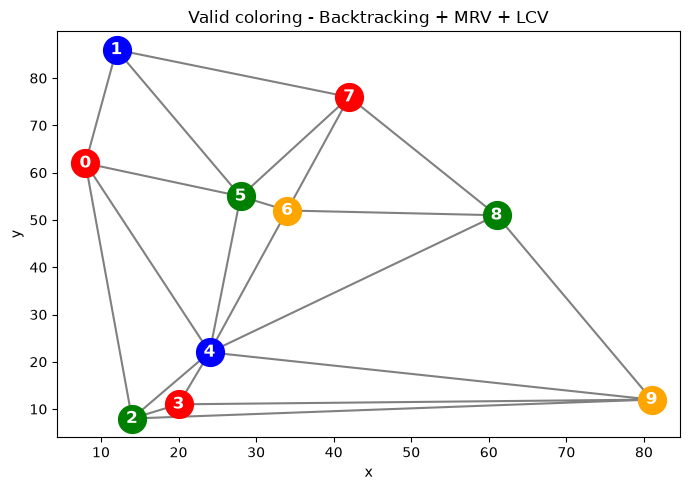

In [9]:
assert is_solution(res, csp_4_colors)

plt.figure(figsize=(7, 5))
plt.triplot(points[:, 0], points[:, 1], tri.simplices, color='gray')

for i in range(len(points)):
    plt.plot(points[i, 0], points[i, 1], 'o', color=res[str(i)], markersize=20)
    plt.annotate(
        i, points[i, :], color='white', fontsize='large', weight='bold',
        horizontalalignment='center', verticalalignment='center'
    )

plt.title('Valid coloring - Backtracking + MRV + LCV')
plt.xlabel('x')
plt.ylabel('y')
plt.tight_layout()
plt.show()

## Bài 4 - Forward Checking và Min-Conflicts

### 4.1. Forward Checking

Sau khi gán màu cho một đỉnh, Forward Checking loại màu đó khỏi miền hiện tại của các láng giềng chưa gán. Nếu một miền trở thành rỗng, nhánh được dừng ngay. Mỗi giá trị bị loại được ghi cùng vị trí ban đầu và được chèn lại khi quay lui, nên miền của nhánh cha được khôi phục chính xác. MRV chọn biến theo kích thước miền hiện tại; LCV ưu tiên màu loại ít giá trị nhất khỏi các láng giềng.

`COUNT` tiếp tục là số lần thử gán biến-giá trị. Ngoài ra ghi số nút, số giá trị bị cắt và trạng thái dừng. `proven_unsat = True` chỉ khi toàn bộ cây tìm kiếm đã được duyệt mà không gặp giới hạn nút.

In [10]:
def forward_checking_search(csp, use_lcv=True, max_nodes=None):
    """Backtracking with MRV, optional LCV, and reversible domain pruning."""
    neighbor_map = build_constraint_neighbors(csp)
    current_domains = {
        variable: list(values)
        for variable, values in csp['domains'].items()
    }
    variable_position = {
        variable: index for index, variable in enumerate(csp['variables'])
    }
    stats = {'count': 0, 'nodes': 0, 'pruned_values': 0, 'cutoff': False}

    def select_mrv(assignment):
        unassigned = [
            variable for variable in csp['variables']
            if variable not in assignment
        ]
        return min(
            unassigned,
            key=lambda variable: (
                len(current_domains[variable]),
                variable_position[variable],
            ),
        )

    def ordered_values(variable, assignment):
        values = list(current_domains[variable])
        if not use_lcv:
            return values
        return sorted(
            values,
            key=lambda value: sum(
                value in current_domains[neighbor]
                for neighbor in neighbor_map[variable]
                if neighbor not in assignment
            ),
        )

    def restore(pruned):
        for variable, value, index in reversed(pruned):
            current_domains[variable].insert(index, value)

    def backtrack(assignment):
        if max_nodes is not None and stats['nodes'] >= max_nodes:
            stats['cutoff'] = True
            return None
        stats['nodes'] += 1

        if complete(assignment, csp):
            return dict(assignment) if consistent(assignment, csp) else None

        variable = select_mrv(assignment)
        if not current_domains[variable]:
            return None

        for value in ordered_values(variable, assignment):
            stats['count'] += 1
            assignment[variable] = value
            pruned = []
            failed = not consistent(assignment, csp)

            if not failed:
                for neighbor in neighbor_map[variable]:
                    if neighbor in assignment or value not in current_domains[neighbor]:
                        continue
                    index = current_domains[neighbor].index(value)
                    current_domains[neighbor].pop(index)
                    pruned.append((neighbor, value, index))
                    stats['pruned_values'] += 1
                    if not current_domains[neighbor]:
                        failed = True
                        break

            result = None if failed else backtrack(assignment)
            restore(pruned)
            del assignment[variable]

            if result is not None:
                return result
            if stats['cutoff']:
                return None

        return None

    start = perf_counter()
    solution = backtrack({})
    runtime_s = perf_counter() - start
    success = solution is not None and is_solution(solution, csp)
    search_complete = not stats['cutoff']

    return {
        'algorithm': 'Forward Checking + MRV + LCV' if use_lcv else 'Forward Checking + MRV',
        'problem': 'graph_coloring',
        'n': len(csp['variables']),
        'num_colors': len(csp['domains'][csp['variables'][0]]),
        'success': success,
        'runtime_s': runtime_s,
        'count': stats['count'],
        'nodes': stats['nodes'],
        'pruned_values': stats['pruned_values'],
        'search_complete': search_complete,
        'proven_unsat': solution is None and search_complete,
        'assignment': solution,
    }

forward_checking_demo = []
for label, model in [('4 colors', csp_4_colors), ('3 colors', csp_3_colors)]:
    result = forward_checking_search(model, use_lcv=True, max_nodes=100_000)
    result['color_model'] = label
    if result['success']:
        assert is_solution(result['assignment'], model)
    forward_checking_demo.append(result)

print(f'{"Model":9} | Success | Proven unsat | COUNT | Nodes | Pruned | Time (ms)')
print('-' * 76)
for result in forward_checking_demo:
    print(
        f'{result["color_model"]:9} | {str(result["success"]):7} | '
        f'{str(result["proven_unsat"]):12} | {result["count"]:5d} | '
        f'{result["nodes"]:5d} | {result["pruned_values"]:6d} | '
        f'{result["runtime_s"] * 1000:9.3f}'
    )

Model     | Success | Proven unsat | COUNT | Nodes | Pruned | Time (ms)
----------------------------------------------------------------------------
4 colors  | True    | False        |    10 |    11 |     20 |     0.518
3 colors  | False   | True         |    33 |    28 |     90 |     0.926


### 4.2. Min-Conflicts

Min-Conflicts bắt đầu từ một phép gán đầy đủ ngẫu nhiên. Ở mỗi bước, thuật toán chọn ngẫu nhiên một biến đang xung đột, tính số xung đột cho từng màu và chọn ngẫu nhiên trong các màu tốt nhất. Thuật toán trả cả phép gán cuối và phép gán tốt nhất đã gặp, cùng `steps`, `evaluations`, `final_conflicts`, `best_conflicts` và `history`.

Min-Conflicts là tìm kiếm cục bộ: `success = False` sau `max_steps` chỉ có nghĩa thuật toán hết ngân sách bước, không chứng minh đồ thị vô nghiệm.

Model     | Success | Steps | Evaluations | Final h | Best h | Time (ms)
-------------------------------------------------------------------------------
4 colors  | True    |     9 |          36 |       0 |      0 |     0.822
3 colors  | False   |  2000 |        6000 |       2 |      2 |   140.128


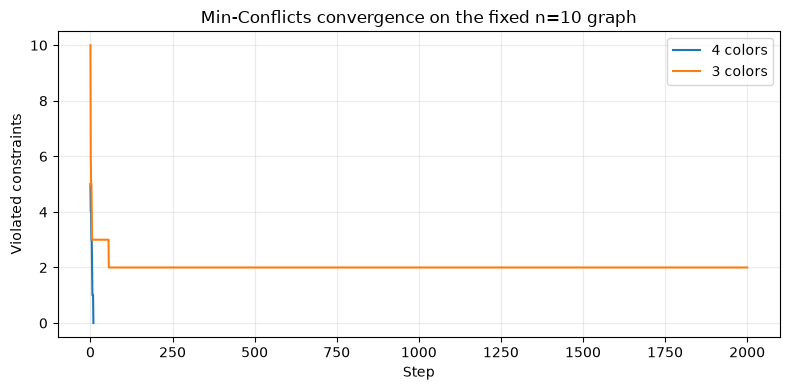

In [11]:
def count_violated_constraints(assignment, csp):
    return sum(
        assignment[first] == assignment[second]
        for first, second in csp['constraints']
    )

def min_conflicts_search(csp, seed, max_steps=2_000, initial_assignment=None):
    """Run Min-Conflicts with random tie-breaking on a complete assignment."""
    rng = np.random.default_rng(seed)
    neighbor_map = build_constraint_neighbors(csp)

    if initial_assignment is None:
        assignment = {
            variable: csp['domains'][variable][
                int(rng.integers(len(csp['domains'][variable])))
            ]
            for variable in csp['variables']
        }
    else:
        assignment = dict(initial_assignment)

    if not complete(assignment, csp):
        raise ValueError('Min-Conflicts requires a complete initial assignment.')

    history = []
    evaluations = 0
    steps = 0
    best_assignment = dict(assignment)
    best_conflicts = count_violated_constraints(assignment, csp)
    start = perf_counter()

    for step in range(max_steps + 1):
        current_conflicts = count_violated_constraints(assignment, csp)
        history.append(current_conflicts)
        if current_conflicts < best_conflicts:
            best_conflicts = current_conflicts
            best_assignment = dict(assignment)
        if current_conflicts == 0 or step == max_steps:
            break

        conflicted_variables = [
            variable for variable in csp['variables']
            if any(
                assignment[variable] == assignment[neighbor]
                for neighbor in neighbor_map[variable]
            )
        ]
        variable = conflicted_variables[int(rng.integers(len(conflicted_variables)))]

        scores = []
        for value in csp['domains'][variable]:
            score = sum(
                assignment[neighbor] == value
                for neighbor in neighbor_map[variable]
            )
            scores.append(score)
            evaluations += 1

        minimum_score = min(scores)
        best_values = [
            value for value, score in zip(csp['domains'][variable], scores)
            if score == minimum_score
        ]
        assignment[variable] = best_values[int(rng.integers(len(best_values)))]
        steps += 1

    runtime_s = perf_counter() - start
    final_conflicts = count_violated_constraints(assignment, csp)
    if final_conflicts < best_conflicts:
        best_conflicts = final_conflicts
        best_assignment = dict(assignment)
    success = best_conflicts == 0

    return {
        'algorithm': 'Min-Conflicts',
        'problem': 'graph_coloring',
        'n': len(csp['variables']),
        'num_colors': len(csp['domains'][csp['variables'][0]]),
        'seed': seed,
        'success': success,
        'runtime_s': runtime_s,
        'steps': steps,
        'evaluations': evaluations,
        'final_conflicts': final_conflicts,
        'best_conflicts': best_conflicts,
        'history': history,
        'assignment': dict(assignment),
        'best_assignment': best_assignment,
    }

min_conflicts_demo = []
for label, model in [('4 colors', csp_4_colors), ('3 colors', csp_3_colors)]:
    result = min_conflicts_search(model, seed=SEED, max_steps=2_000)
    result['color_model'] = label
    if result['success']:
        assert is_solution(result['best_assignment'], model)
    min_conflicts_demo.append(result)

print(f'{"Model":9} | Success | Steps | Evaluations | Final h | Best h | Time (ms)')
print('-' * 79)
for result in min_conflicts_demo:
    print(
        f'{result["color_model"]:9} | {str(result["success"]):7} | '
        f'{result["steps"]:5d} | {result["evaluations"]:11d} | '
        f'{result["final_conflicts"]:7d} | {result["best_conflicts"]:6d} | '
        f'{result["runtime_s"] * 1000:9.3f}'
    )

plt.figure(figsize=(8, 4))
for result in min_conflicts_demo:
    plt.plot(result['history'], label=result['color_model'])
plt.xlabel('Step')
plt.ylabel('Violated constraints')
plt.title('Min-Conflicts convergence on the fixed n=10 graph')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### 4.3. Thí nghiệm nhiều kích thước, seed và số màu

Thí nghiệm dùng `n in {10, 20, 30}`, ba seed cho mỗi kích thước và cùng một đồ thị cho hai thuật toán tại mỗi cấu hình. Forward Checking có `max_nodes = 50_000`; Min-Conflicts có `max_steps = 3_000`. Bảng tổng hợp báo số cạnh trung bình, tỷ lệ thành công, nỗ lực tìm kiếm trung bình, xung đột tốt nhất và thời gian.

In [12]:
from statistics import mean

def generate_planar_graph_instance(n, seed):
    """Generate one reproducible planar Delaunay graph."""
    rng = np.random.default_rng(seed)
    instance_points = rng.random((n, 2))
    instance_tri = Delaunay(instance_points)
    indptr, indices = instance_tri.vertex_neighbor_vertices
    instance_neighbors = [
        np.sort(indices[indptr[index]:indptr[index + 1]])
        for index in range(n)
    ]
    instance_edges = [
        (i, int(j))
        for i, adjacent_vertices in enumerate(instance_neighbors)
        for j in adjacent_vertices
        if i < int(j)
    ]
    assert sum(len(values) for values in instance_neighbors) == 2 * len(instance_edges)
    return instance_points, instance_tri, instance_neighbors, instance_edges

experiment_sizes = (10, 20, 30)
experiment_seeds = (1111, 2222, 3333)
experiment_records = []

for instance_n in experiment_sizes:
    for instance_seed in experiment_seeds:
        _, _, instance_neighbors, instance_edges = generate_planar_graph_instance(
            instance_n, instance_seed
        )
        for colors in (COLORS_3, COLORS_4):
            model = build_graph_coloring_csp(instance_neighbors, colors)

            fc_result = forward_checking_search(
                model, use_lcv=True, max_nodes=50_000
            )
            if fc_result['success']:
                assert is_solution(fc_result['assignment'], model)
            experiment_records.append({
                **fc_result,
                'seed': instance_seed,
                'num_edges': len(instance_edges),
                'effort': fc_result['count'],
                'best_conflicts': 0 if fc_result['success'] else None,
                'status': (
                    'success' if fc_result['success']
                    else 'proven_unsat' if fc_result['proven_unsat']
                    else 'node_limit'
                ),
            })

            mc_result = min_conflicts_search(
                model, seed=instance_seed + 10_000 * len(colors), max_steps=3_000
            )
            if mc_result['success']:
                assert is_solution(mc_result['best_assignment'], model)
            experiment_records.append({
                **mc_result,
                'seed': instance_seed,
                'num_edges': len(instance_edges),
                'effort': mc_result['steps'],
                'status': 'success' if mc_result['success'] else 'step_limit',
            })

print(f'Completed {len(experiment_records)} algorithm runs.')

Completed 36 algorithm runs.


In [13]:
summary_rows = []
for algorithm in ('Forward Checking + MRV + LCV', 'Min-Conflicts'):
    for instance_n in experiment_sizes:
        for num_colors in (3, 4):
            group = [
                record for record in experiment_records
                if record['algorithm'] == algorithm
                and record['n'] == instance_n
                and record['num_colors'] == num_colors
            ]
            status_counts = {
                status: sum(record['status'] == status for record in group)
                for status in sorted({record['status'] for record in group})
            }
            conflicts = [
                record['best_conflicts']
                for record in group
                if record['best_conflicts'] is not None
            ]
            summary_rows.append({
                'algorithm': algorithm,
                'n': instance_n,
                'num_colors': num_colors,
                'runs': len(group),
                'mean_edges': mean(record['num_edges'] for record in group),
                'success_rate': 100 * mean(record['success'] for record in group),
                'mean_effort': mean(record['effort'] for record in group),
                'mean_best_conflicts': mean(conflicts) if conflicts else None,
                'mean_runtime_ms': 1000 * mean(record['runtime_s'] for record in group),
                'statuses': ', '.join(
                    f'{status}:{count}' for status, count in status_counts.items()
                ),
            })

print(
    f'{"Algorithm":28} | n  | k | Runs | Edges | Success | Effort | '
    f'{"Best h":7} | {"Time ms":8} | Statuses'
)
print('-' * 125)
for row in summary_rows:
    best_h = '-' if row['mean_best_conflicts'] is None else f'{row["mean_best_conflicts"]:.2f}'
    print(
        f'{row["algorithm"]:28} | {row["n"]:2d} | {row["num_colors"]:1d} | '
        f'{row["runs"]:4d} | {row["mean_edges"]:5.1f} | '
        f'{row["success_rate"]:6.1f}% | {row["mean_effort"]:6.1f} | '
        f'{best_h:7} | {row["mean_runtime_ms"]:8.3f} | {row["statuses"]}'
    )

assert len(experiment_records) == len(experiment_sizes) * len(experiment_seeds) * 2 * 2
assert all(
    not record['success'] or record['best_conflicts'] in (0, None)
    for record in experiment_records
)

Algorithm                    | n  | k | Runs | Edges | Success | Effort | Best h  | Time ms  | Statuses
-----------------------------------------------------------------------------------------------------------------------------
Forward Checking + MRV + LCV | 10 | 3 |    3 |  20.7 |    0.0% |   31.0 | -       |    0.916 | proven_unsat:3
Forward Checking + MRV + LCV | 10 | 4 |    3 |  20.7 |  100.0% |   10.0 | 0.00    |    0.407 | success:3
Forward Checking + MRV + LCV | 20 | 3 |    3 |  50.3 |    0.0% |   37.0 | -       |    1.386 | proven_unsat:3
Forward Checking + MRV + LCV | 20 | 4 |    3 |  50.3 |  100.0% |   20.0 | 0.00    |    1.265 | success:3
Forward Checking + MRV + LCV | 30 | 3 |    3 |  78.7 |    0.0% |   51.0 | -       |    2.757 | proven_unsat:3
Forward Checking + MRV + LCV | 30 | 4 |    3 |  78.7 |  100.0% |   37.7 | 0.00    |    3.020 | success:3
Min-Conflicts                | 10 | 3 |    3 |  20.7 |    0.0% | 3000.0 | 1.33    |  189.169 | step_limit:3
Min-Conflicts    

### 4.4. Nhận xét

- Trên đồ thị cố định `n = 10`, Forward Checking tìm nghiệm 4 màu với `COUNT = 10`, 11 nút và 20 lượt cắt miền. Với 3 màu, thuật toán duyệt hoàn chỉnh và chứng minh vô nghiệm sau 33 lần thử, 28 nút và 90 lượt cắt miền.
- Cũng trên đồ thị này, Min-Conflicts tìm nghiệm 4 màu sau 9 bước. Với 3 màu, thuật toán hết 2.000 bước và nghiệm tốt nhất còn 2 cạnh vi phạm; đây chỉ là thất bại trong ngân sách bước.
- Trong benchmark 36 lượt, số cạnh trung bình lần lượt là 20,7; 50,3; 78,7 cho `n = 10, 20, 30`. Forward Checking đạt 100% với 4 màu và chứng minh vô nghiệm cho cả ba seed ở mỗi kích thước với 3 màu.
- Min-Conflicts đạt 100% trên các instance 4 màu đã thử. Với 3 màu, cả chín lượt đều hết giới hạn 3.000 bước; số xung đột tốt nhất trung bình lần lượt là 1,33; 3,67; 5,67. Không được dùng riêng kết quả này để kết luận vô nghiệm.
- Các tỷ lệ trên chỉ mô tả ba seed và ba kích thước đã khảo sát, không phải bảo đảm cho mọi đồ thị phẳng. Thời gian phụ thuộc máy và cài đặt; `COUNT`, `nodes`, `steps` và `evaluations` có định nghĩa khác nhau nên không so sánh trực tiếp như cùng một đại lượng.